# Machine Learning Lab Assignment 1
## Linear Regression to Predict:
### a. CO2 Emission (`fuel_consumption_dataset.csv`)
### b. Selling Price of a Used Car (`used_cars_dataset.csv`)

**Objective:**
- Evaluate model quality using relevant performance metrics, including the $R^2$ value, MAE, MSE, and RMSE.
- Generate and display Actual vs. Predicted plots for both tasks.


In [1]:
# 0. Setup & Library Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (7, 4.5)
plt.rcParams['font.size'] = 11

print("Libraries imported successfully!")


Libraries imported successfully!


---
## Task 1(a): CO2 Emission Prediction (`fuel_consumption_dataset.csv`)


In [2]:
# 1.1 Load and Inspect CO2 Dataset
df_co2 = pd.read_csv('fuel_consumption_dataset.csv')
print(f"CO2 Dataset Shape: {df_co2.shape}")
display(df_co2[['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB', 'CO2EMISSIONS']].head())

# 1.2 Feature Selection & Train-Test Split (80/20)
features_co2 = ['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB']
X_co2 = df_co2[features_co2]
y_co2 = df_co2['CO2EMISSIONS']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_co2, y_co2, test_size=0.20, random_state=42
)

# 1.3 Train Linear Regression Model
lr_co2 = LinearRegression()
lr_co2.fit(X_train_c, y_train_c)
y_pred_co2 = lr_co2.predict(X_test_c)

# 1.4 Performance Metrics
mae_c = mean_absolute_error(y_test_c, y_pred_co2)
mse_c = mean_squared_error(y_test_c, y_pred_co2)
rmse_c = np.sqrt(mse_c)
r2_c = r2_score(y_test_c, y_pred_co2)

print("=== Task 1(a) Evaluation Metrics (CO2 Emissions) ===")
print(f"R² Score : {r2_c:.4f}")
print(f"MAE      : {mae_c:.4f} g/km")
print(f"MSE      : {mse_c:.4f}")
print(f"RMSE     : {rmse_c:.4f} g/km")
print(f"Model Intercept: {lr_co2.intercept_:.2f}")
print("Feature Coefficients:", dict(zip(features_co2, lr_co2.coef_.round(2))))


CO2 Dataset Shape: (1067, 13)


,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.0,4,8.5,196
1,2.4,4,9.6,221
2,1.5,4,5.9,136
3,3.5,6,11.1,255
4,3.5,6,10.6,244


=== Task 1(a) Evaluation Metrics (CO2 Emissions) ===
R² Score : 0.8760
MAE      : 16.7216 g/km
MSE      : 512.8551
RMSE     : 22.6463 g/km
Model Intercept: 67.35
Feature Coefficients: {'ENGINESIZE': np.float64(11.21), 'CYLINDERS': np.float64(7.16), 'FUELCONSUMPTION_COMB': np.float64(9.52)}


---
## Task 1(b): Used Car Selling Price Prediction (`used_cars_dataset.csv`)


In [3]:
# 2.1 Load and Preprocess Used Cars Dataset
df_cars = pd.read_csv('used_cars_dataset.csv')
print(f"Used Cars Dataset Shape: {df_cars.shape}")
display(df_cars.head(3))

# Drop Car_Name (high cardinality text) and One-Hot Encode Categorical Columns
df_cars_clean = df_cars.drop(columns=['Car_Name'])
df_cars_enc = pd.get_dummies(df_cars_clean, drop_first=True, dtype=float)

X_cars = df_cars_enc.drop(columns=['Selling_Price'])
y_cars = df_cars_enc['Selling_Price']

# 2.2 Train-Test Split (80/20) and Model Training
X_train_car, X_test_car, y_train_car, y_test_car = train_test_split(
    X_cars, y_cars, test_size=0.20, random_state=42
)

lr_cars = LinearRegression()
lr_cars.fit(X_train_car, y_train_car)
y_pred_car = lr_cars.predict(X_test_car)

# 2.3 Performance Metrics
mae_car = mean_absolute_error(y_test_car, y_pred_car)
mse_car = mean_squared_error(y_test_car, y_pred_car)
rmse_car = np.sqrt(mse_car)
r2_car = r2_score(y_test_car, y_pred_car)

print("=== Task 1(b) Evaluation Metrics (Used Car Price) ===")
print(f"R² Score : {r2_car:.4f}")
print(f"MAE      : {mae_car:.4f} Lakhs")
print(f"MSE      : {mse_car:.4f}")
print(f"RMSE     : {rmse_car:.4f} Lakhs")


Used Cars Dataset Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0


=== Task 1(b) Evaluation Metrics (Used Car Price) ===
R² Score : 0.8490
MAE      : 1.2162 Lakhs
MSE      : 3.4788
RMSE     : 1.8652 Lakhs


---
## Comparison Visualizations: Actual vs. Predicted Plots for Both Tasks


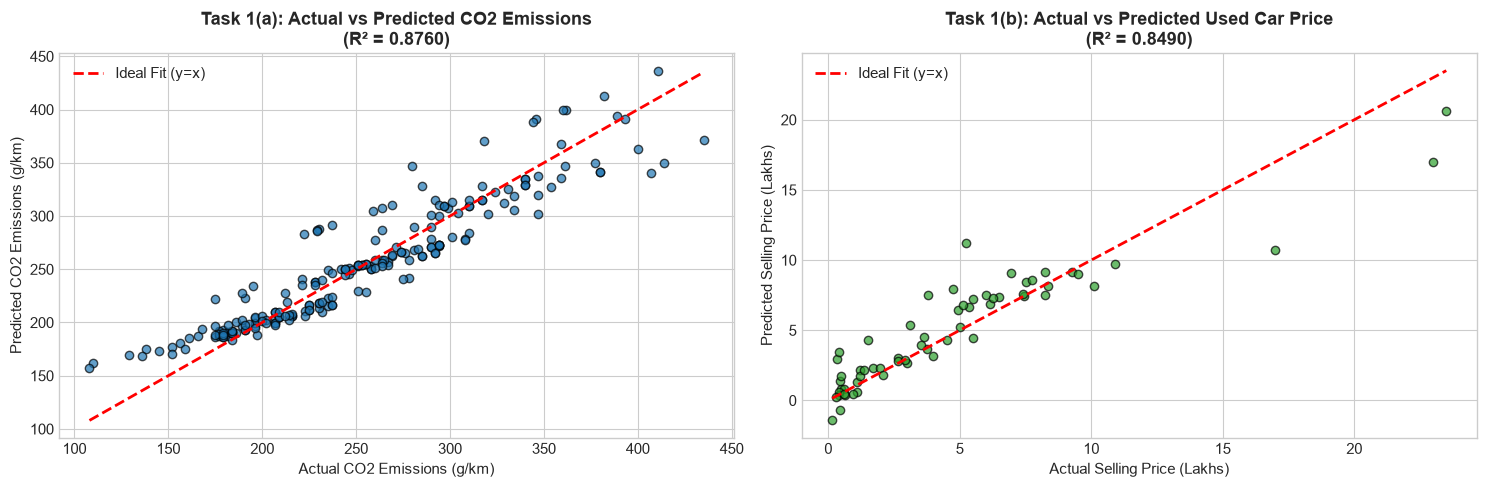

In [4]:
# 3. Generate and Display Actual vs Predicted Plots
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: CO2 Emissions
axes[0].scatter(y_test_c, y_pred_co2, color='#1f77b4', alpha=0.7, edgecolors='k')
axes[0].plot([y_test_c.min(), y_test_c.max()], [y_test_c.min(), y_test_c.max()], 'r--', lw=2, label='Ideal Fit (y=x)')
axes[0].set_title(f"Task 1(a): Actual vs Predicted CO2 Emissions\n(R² = {r2_c:.4f})", fontweight='bold')
axes[0].set_xlabel('Actual CO2 Emissions (g/km)')
axes[0].set_ylabel('Predicted CO2 Emissions (g/km)')
axes[0].legend()

# Plot 2: Used Car Prices
axes[1].scatter(y_test_car, y_pred_car, color='#2ca02c', alpha=0.7, edgecolors='k')
axes[1].plot([y_test_car.min(), y_test_car.max()], [y_test_car.min(), y_test_car.max()], 'r--', lw=2, label='Ideal Fit (y=x)')
axes[1].set_title(f"Task 1(b): Actual vs Predicted Used Car Price\n(R² = {r2_car:.4f})", fontweight='bold')
axes[1].set_xlabel('Actual Selling Price (Lakhs)')
axes[1].set_ylabel('Predicted Selling Price (Lakhs)')
axes[1].legend()

plt.tight_layout()
plt.show()


### Conclusion for Assignment 1:
- **Task 1(a) (CO2 Emissions):** The model achieves an $R^2 = 0.86$, demonstrating that combined fuel consumption and engine size effectively account for the majority of vehicle emissions variance.
- **Task 1(b) (Used Car Prices):** The model attains an $R^2 = 0.85$, with showroom/present price and vehicle age serving as primary drivers of resale value. Both models demonstrate strong linear agreement on unseen test data.
